# 04 · Dose diagnostics: a flat second patch, or a faulty measuring stick

Phase 5, a robustness check on the dose-response in notebook 02 (section 8). It reads the
saved fits (`data/analysis/did_h3.parquet`) and `reference/tweak_sizes.csv`. **No database, no
refitting: it should run in seconds.**

**The question.** In notebook 02 the first patch shows bigger change, bigger effect. The second
patch doesn't: its slope is about zero, and its points sit lower than the first-patch line.
Two very different stories could produce that.

1. **The patch really did something different.** Something about the second patch's design
   (a short "before" period, carryover from the first patch) moves every card by roughly the
   same amount, whatever the size of its change.
2. **Our measuring stick is off.** The *dose* (how big a change was) is defined as
   `direction × ln(new/old)` of one number per card. If that is a poor stand-in for "how hard
   the change hit", the slope can look flat even when real effects exist.

**Plain-language picture.** Think of pushing kids on swings. The *dose* is how hard you push and
the *response* is how high the swing goes. A flat line means "a harder push doesn't make it go
higher". Before you conclude that swings don't respond, check that you measured the push
properly: in newtons, not in how tired your arm felt, and with no kid jumping off mid-swing to
skew the picture. This notebook runs those checks.

**Terms**
- *dose*: size of the change, `x`. *response*: the effect on pick rate, `y` (log-odds).
- *slope*: how much the response grows per unit of dose. *shift*: how far a whole patch sits
  above or below the other at the same dose.
- *z*: an estimate divided by its error bar. Roughly, |z| above 2 means "clearly not zero".
- *leverage*: one point with so much pull on the line that removing it changes the answer.
- *residual*: how far a point sits from a line.

**The rule about forking paths.** Below are twelve ways to redefine the dose or the sample.
If you try nine and report only the one that looks good, you have probably found noise. So
every variant goes into one table and is read together, with `z_diff` (section 3) as the main
column.

Sections: 0 setup · 1 the points · 2 who is in the sample · 3 variants · 4 leave one out ·
5 predict patch 2 from patch 1 · 6 slopes by kind of number · 7 limits.

*Version 2 adds three dose definitions (percent change, units of the kind's typical change,
buff/nerf only) and `slope_diff` / `z_diff`: patch 2's slope minus patch 1's, with its error
bar. That is the real question. `z_second` only asks whether patch 2's slope is zero, which a
wide error bar can never answer.*

## 0. Setup

In [ ]:
import os
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
if not (ROOT / "reference").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

from spirometry.meta import meta_regression, designs, dose_response_fits

REF = ROOT / "reference"
OUT = ROOT / "data" / "analysis"          # git-ignored (data/)
H_PATH = OUT / "did_h3.parquet"           # notebook 02, section 6b: weeks 0-3 after the release
SECOND_BEFORE = "v0.103.3"                # the second patch's before build (as in notebook 02)

plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.5, "lines.markersize": 4,
})
pd.set_option("display.width", 160, "display.max_columns", 40, "display.max_rows", 120)
TREATED_C, CONTROL_C, GREY = "#e8702a", "#2a6fdb", "#555555"   # same colors as 01 to 03
FIRST, SECOND = "first patch", "second patch"

if not H_PATH.exists():
    raise SystemExit(f"{H_PATH} not found. Run notebook 02 (section 6b) first.")
H = pd.read_parquet(H_PATH)
if "card_patch_id" in H.columns:
    H = H.set_index("card_patch_id")
TW = pd.read_csv(REF / "tweak_sizes.csv", dtype=str, keep_default_na=False).set_index("card_patch_id")
print(f"{len(H)} fitted tweaks in {H_PATH.name}; {len(TW)} rows in tweak_sizes.csv")

43 fitted tweaks in did_h3.parquet; 50 rows in tweak_sizes.csv


## 1. The points

One row per tweak, built the same way as notebook 02 section 8:

- keep tweaks that fit without error,
- drop *mixed-direction* tweaks (one number up, another down, so no single dose),
- drop *upgrade-only* tweaks (their dose is a different kind of number),
- drop tweaks with no dose or no log-odds estimate.

Extra columns for this notebook:

- `x_abs`: the absolute change, `direction × (new − old)`, in place of the ratio.
- `x_pct`: percent change as a fraction, `direction × (new − old) / old`. Close to `ln` for small
  changes, but +50% and −33% are no longer mirror images.
- `x_kind`: `ln` divided by the typical |ln| of that kind of number, so "1" means "a typical
  damage change" for damage and "a typical block change" for block.
- `x_sign`: +1 for a buff, −1 for a nerf, ignoring size entirely.
- `kind`: what sort of number was changed (damage, block, a power's amount, or other).
- `both_patches`: the card was changed in *both* patches. Its second-patch "before" period
  still contains the first patch's effect (carryover).
- `beta_pp`, `se_pp`: the effect back in percentage points (as a fraction of offers), undoing
  the log-odds conversion, so we can test whether that conversion matters.

**First check:** the baseline fit below should match notebook 02's "slope per patch" rows.
If not, stop and find out why before reading anything else.

In [ ]:
need = ["card_id", "error", "beta", "se", "beta_lo", "se_lo", "direction", "log_ratio",
        "mixed_direction", "upgrade_only", "before_builds"]
missing = [c for c in need if c not in H.columns]
assert not missing, f"did_h3.parquet is missing {missing}"

m = H[H.error == ""][need].join(TW[["main_field", "old", "new"]])

def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace("+", "", regex=False), errors="coerce")

def kind_of(field):
    if field == "damage":
        return "damage"
    if field == "block":
        return "block"
    if str(field).startswith("powers_applied"):
        return "power amount"
    return "other"          # Forge, energy_gain, ExtraDamage, Increase, ... (a grab-bag)

m["x"] = m.direction * m.log_ratio
m["x_abs"] = m.direction * (to_num(m.new) - to_num(m.old))
m["kind"] = m.main_field.map(kind_of)

line = m[(m.mixed_direction != "yes") & (m.upgrade_only != "yes")
         & m.x.notna() & m.beta_lo.notna() & (m.se_lo > 0)].copy()
line["second"] = (line.before_builds == SECOND_BEFORE).astype(float)
line["patch"] = np.where(line.second == 1, SECOND, FIRST)

# percentage-point version of the same estimates: beta_lo = beta / k with k = p (1 - p)
k = (line.beta / line.beta_lo).abs()
line["beta_pp"] = line.beta
line["se_pp"] = line.se_lo * k
line["x_rank"] = line.x.rank(pct=True) - 0.5      # only the ordering of the doses survives
line["x_pct"] = (line.direction * (to_num(line.new) - to_num(line.old)) / to_num(line.old)
                 ).replace([np.inf, -np.inf], np.nan)      # signed percent change as a fraction
line["x_kind"] = line.x / line.groupby("kind").x.transform(lambda s: s.abs().median())
line["x_sign"] = np.sign(line.x)                   # buff = +1, nerf = -1, no size at all

g = TW.groupby("card_id").before_builds.nunique()
BOTH = set(g[g > 1].index)
line["both_patches"] = line.card_id.isin(BOTH)

print(f"{len(line)} tweaks on the line: {int((line.second == 0).sum())} first patch, "
      f"{int(line.second.sum())} second patch; {int((line.x < 0).sum())} nerfs")
print("left off:", sorted(set(m.card_id) - set(line.card_id)))
same_sign = (np.sign(line.x_abs.dropna()) == np.sign(line.x[line.x_abs.notna()])).all()
print("absolute and ratio doses agree in sign everywhere:", bool(same_sign))

base = dose_response_fits(line.beta_lo, line.se_lo, line.x, line.second)
display(base[base.model == "slope per patch"][["term_label", "coef", "se", "z", "tau2"]]
        .set_index("term_label").round(4))

38 tweaks on the line: 24 first patch, 14 second patch; 8 nerfs
left off: ['LEADING_STRIKE', 'REFLECT', 'ROYALTIES', 'SERPENT_FORM']
absolute and ratio doses agree in sign everywhere: True


,coef,se,z,tau2
term_label,,,,
intercept a,-0.0252,0.0516,-0.4879,0.0511
second-patch shift c,0.0718,0.0898,0.7997,0.0511
"slope, first patch",1.4402,0.1928,7.4711,0.0511
"slope, second patch",0.0383,0.3086,0.1240,0.0511


## 2. Who is in the sample

Before testing anything, look at what the two patches contain. If one patch is mostly damage
changes and the other mostly power amounts, a single slope compares unlike things.
`kind` groups the main field: damage, block, power amount, and "other" (a grab-bag of rarer
fields, so don't read much into its slope).

In [ ]:
print("tweaks on the line, by kind and patch")
display(pd.crosstab(line.kind, line.patch))
print("median |dose| (ln ratio), by kind and patch")
display(line.assign(a=line.x.abs()).pivot_table(index="kind", columns="patch", values="a",
                                                aggfunc="median").round(3))
print("buffs / nerfs by patch")
display(pd.crosstab(line.patch, np.where(line.x > 0, "buff", "nerf")))
print("cards changed in both patches, and how they look in each")
display(line[line.both_patches].sort_values(["card_id", "second"])
        [["card_id", "patch", "kind", "x", "beta_lo", "se_lo"]].round(3))

tweaks on the line, by kind and patch


patch,first patch,second patch
kind,,
block,4,2
damage,12,6
other,4,3
power amount,4,3


median |dose| (ln ratio), by kind and patch


patch,first patch,second patch
kind,,
block,0.126,0.099
damage,0.129,0.154
other,0.371,0.288
power amount,0.406,0.406


buffs / nerfs by patch


col_0,buff,nerf
patch,,
first patch,19,5
second patch,11,3


cards changed in both patches, and how they look in each


,card_id,patch,kind,x,beta_lo,se_lo
card_patch_id,,,,,,
DEBILITATE@v0.103.2/patch,DEBILITATE,first patch,damage,0.357,0.398,0.055
DEBILITATE@v0.107.1/patch,DEBILITATE,second patch,power amount,-0.406,0.122,0.048
PATTER@v0.103.2/patch,PATTER,first patch,block,0.118,0.299,0.040
PATTER@v0.107.1/patch,PATTER,second patch,block,-0.118,-0.161,0.036
UNTOUCHABLE@v0.103.2/patch,UNTOUCHABLE,first patch,block,-0.406,-0.397,0.025


## 3. The variants

Every row is the same model as notebook 02's "slope per patch": a common intercept, a
second-patch shift, and one slope per patch. Only the input changes.

| variant | what it tests |
|---|---|
| baseline | the notebook 02 answer |
| outcome in pp | whether the conversion to log-odds (`beta / (p(1−p))`, notebook 02 section 8) distorts things |
| dose = new − old | whether it matters that we use a ratio, not an absolute change |
| dose = rank | throws away the size and keeps only the ordering: tests for any monotone trend at all (intercept is now at the median dose, so read the shift carefully) |
| dose = percent change | whether log versus plain percent matters |
| dose = in units of kind's typical change | puts damage, block and power amounts on a common footing |
| dose = buff/nerf only | no size at all: whether buffs beat nerfs by a fixed amount |
| drop both-patch cards | carryover from the first patch (Debilitate, Patter, Untouchable) |
| damage and block only | the two most comparable kinds of number |
| damage only | the largest single kind |
| drop power amounts | their doses are on a larger scale (median about 0.4 against 0.1 to 0.15) |
| buffs only | removes the wrong-sign nerfs that have large leverage |

**How to read it.**

- `z_diff` is the key column: patch 2's slope minus patch 1's, divided by its error bar
  (including the covariance between the two). |z| above 2 means the patches clearly differ.
- `z_second` only asks whether patch 2's slope is zero. With about 14 points the error bar
  (`se_second`) is wide, so it rarely can say anything. Keep it for reference.
- If `z_diff` stays large across rulers, the flat patch 2 isn't an artifact of the dose
  definition. If it collapses in some rows, check whether those rows also have huge error bars
  (then they say nothing) or a different, sensible ruler (then the ruler mattered).
- Slopes are in different units across rows, so compare z columns, not raw slopes.

In [ ]:
def run_variant(name, d, y="beta_lo", s="se_lo", x="x"):
    d = d[d[x].notna() & d[y].notna() & (d[s] > 0)]
    sec = d.second.to_numpy()
    out = dict(variant=name, n_first=int((sec == 0).sum()), n_second=int(sec.sum()))
    cols = ["slope_first", "se_first", "slope_second", "se_second", "patch_shift", "se_shift",
            "tau2", "slope_diff", "se_diff"]
    try:
        if out["n_second"] < 3 or out["n_first"] < 3:
            raise ValueError("too few points")
        X = designs(d[x], sec)["slope per patch"]     # columns: a, shift, slope 1st, slope 2nd
        b, se, tau2, Q, dof = meta_regression(d[y], d[s], X)
        ws = 1 / (d[s].to_numpy() ** 2 + tau2)
        cov = np.linalg.inv((X.T * ws) @ X)
        c = np.array([0.0, 0.0, -1.0, 1.0])               # slope_second - slope_first
        out.update(slope_diff=float(c @ b), se_diff=float(np.sqrt(c @ cov @ c)), slope_first=b[2], se_first=se[2], slope_second=b[3], se_second=se[3],
                   patch_shift=b[1], se_shift=se[1], tau2=tau2)
    except (np.linalg.LinAlgError, ValueError):
        out.update({c: np.nan for c in cols})
    out["z_first"] = out["slope_first"] / out["se_first"]
    out["z_second"] = out["slope_second"] / out["se_second"]
    out["z_diff"] = out["slope_diff"] / out["se_diff"]
    out["z_shift"] = out["patch_shift"] / out["se_shift"]
    return out

VARIANTS = [
    ("baseline: log-odds, ln(new/old)", line, {}),
    ("outcome in pp (not log-odds)", line, dict(y="beta_pp", s="se_pp")),
    ("dose = new - old (absolute)", line, dict(x="x_abs")),
    ("dose = rank only", line, dict(x="x_rank")),
    ("dose = percent change", line, dict(x="x_pct")),
    ("dose = ln in units of kind's typical change", line, dict(x="x_kind")),
    ("dose = buff/nerf only (sign)", line, dict(x="x_sign")),
    ("drop cards changed in both patches", line[~line.both_patches], {}),
    ("damage and block only", line[line.kind.isin(["damage", "block"])], {}),
    ("damage only", line[line.kind == "damage"], {}),
    ("drop power amounts", line[line.kind != "power amount"], {}),
    ("buffs only", line[line.x > 0], {}),
]
VAR = pd.DataFrame([run_variant(n, d, **kw) for n, d, kw in VARIANTS])
SHOW = ["n_first", "n_second", "slope_first", "se_first", "slope_second", "se_second",
        "slope_diff", "se_diff", "z_diff", "z_second", "patch_shift", "se_shift", "z_shift", "tau2"]
display(VAR.set_index("variant")[SHOW].round(3))

,n_first,n_second,slope_first,se_first,slope_second,se_second,slope_diff,se_diff,z_diff,z_second,patch_shift,se_shift,z_shift,tau2
variant,,,,,,,,,,,,,,
"baseline: log-odds, ln(new/old)",24,14,1.440,0.193,0.038,0.309,-1.402,0.364,-3.853,0.124,0.072,0.090,0.800,0.051
outcome in pp (not log-odds),24,14,0.216,0.026,-0.001,0.043,-0.217,0.050,-4.338,-0.013,0.023,0.012,1.892,0.001
dose = new - old (absolute),24,14,0.054,0.024,0.019,0.069,-0.036,0.073,-0.489,0.270,-0.022,0.119,-0.182,0.077
dose = rank only,24,14,1.170,0.156,0.054,0.234,-1.116,0.281,-3.974,0.229,-0.089,0.078,-1.142,0.050
dose = percent change,24,14,1.422,0.177,0.049,0.288,-1.373,0.338,-4.063,0.171,0.121,0.091,1.326,0.047
dose = ln in units of kind's typical change,24,14,0.230,0.046,0.037,0.086,-0.193,0.097,-1.983,0.435,0.013,0.105,0.126,0.069
dose = buff/nerf only (sign),24,14,0.352,0.063,0.026,0.081,-0.326,0.103,-3.175,0.324,0.111,0.103,1.082,0.060
drop cards changed in both patches,21,12,1.567,0.234,-0.019,0.605,-1.586,0.649,-2.443,-0.032,0.121,0.150,0.806,0.058
damage and block only,16,8,1.237,0.341,0.472,0.636,-0.765,0.722,-1.060,0.743,0.088,0.122,0.723,0.051


**Plot.** Left: z for the *difference* between the patches' slopes
in every variant (the one that matters). Middle: z for the second-patch slope alone. Right:
z for the second-patch shift. The shaded band is |z| < 2, "not clearly different from zero".
Variants where the point sits outside the band on the left are the ones where the dose
definition mattered.

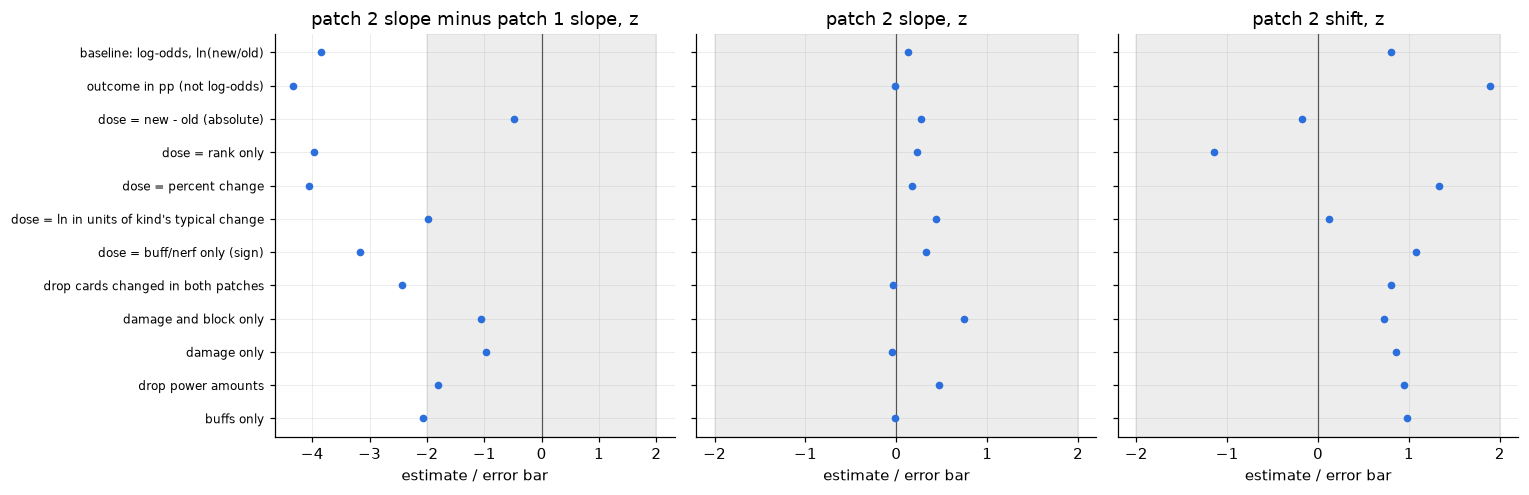

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
ypos = np.arange(len(VAR))[::-1]
for ax, col, title in [(axes[0], "z_diff", "patch 2 slope minus patch 1 slope, z"),
                       (axes[1], "z_second", "patch 2 slope, z"),
                       (axes[2], "z_shift", "patch 2 shift, z")]:
    ax.axvspan(-2, 2, color=GREY, alpha=0.10)
    ax.axvline(0, color=GREY, lw=0.8)
    ax.scatter(VAR[col], ypos, color=CONTROL_C, zorder=3)
    ax.set(title=title, xlabel="estimate / error bar")
axes[0].set_yticks(ypos, VAR.variant, fontsize=8)
plt.tight_layout()
plt.show()

## 4. Leave one out

Refit the model once per tweak, each time with that one tweak removed. The picture is a
see-saw: if taking one kid off changes which way it tips, that kid had *leverage*. If
removing any one point barely moves the answer, no single card is carrying the result.

Watch two things: whether the second-patch slope ever becomes clearly positive, and whether
the shift ever shrinks toward zero. Debilitate (a nerf whose effect has the wrong sign for its
dose) is the likeliest source of leverage, but the table will tell you rather than guess.

In [ ]:
rows = []
for cpid, r in line.iterrows():
    v = run_variant(f"without {r.card_id}", line.drop(index=cpid))
    v.update(dropped=r.card_id, dropped_patch=r.patch, dropped_x=r.x, dropped_y=r.beta_lo)
    rows.append(v)
LOO = pd.DataFrame(rows)
b0 = VAR.iloc[0]
LOO["d_slope_second"] = LOO.slope_second - b0.slope_second
LOO["d_shift"] = LOO.patch_shift - b0.patch_shift
print(f"baseline: slope_second {b0.slope_second:.3f}, shift {b0.patch_shift:.3f}")
print(f"leave-one-out range: slope_second {LOO.slope_second.min():.3f} to "
      f"{LOO.slope_second.max():.3f}; shift {LOO.patch_shift.min():.3f} to {LOO.patch_shift.max():.3f}")
print(f"baseline z_diff {b0.z_diff:.2f}; leave-one-out range {LOO.z_diff.min():.2f} to {LOO.z_diff.max():.2f}")
display(LOO.reindex(LOO.d_slope_second.abs().sort_values(ascending=False).index).head(10)
        [["dropped", "dropped_patch", "dropped_x", "dropped_y", "slope_second", "z_second",
          "patch_shift", "z_shift", "z_diff", "d_slope_second", "d_shift"]].round(3))

baseline: slope_second 0.038, shift 0.072
leave-one-out range: slope_second -0.072 to 0.244; shift 0.030 to 0.105
baseline z_diff -3.85; leave-one-out range -4.10 to -2.39


,dropped,dropped_patch,dropped_x,dropped_y,slope_second,z_second,patch_shift,z_shift,z_diff,d_slope_second,d_shift
29,DEBILITATE,second patch,-0.406,0.122,0.244,0.528,0.030,0.264,-2.391,0.205,-0.042
27,PATTER,second patch,-0.118,-0.161,-0.072,-0.220,0.104,1.090,-3.974,-0.110,0.032
30,SIC_EM,second patch,0.406,0.135,-0.007,-0.021,0.071,0.781,-3.713,-0.046,-0.001
31,THE_SCYTHE,second patch,0.288,-0.049,0.072,0.225,0.076,0.837,-3.673,0.033,0.004
25,CRESCENT_SPEAR,second patch,0.288,-0.038,0.070,0.218,0.076,0.828,-3.646,0.032,0.004
34,UPROAR,second patch,0.182,0.297,0.013,0.041,0.056,0.620,-3.925,-0.026,-0.016
26,FURNACE,second patch,0.223,-0.047,0.057,0.183,0.077,0.845,-3.736,0.019,0.006
28,DEATH_MARCH,second patch,0.288,0.106,0.023,0.072,0.070,0.769,-3.801,-0.015,-0.002
35,JUGGERNAUT,second patch,0.182,-0.077,0.052,0.167,0.080,0.875,-3.784,0.014,0.008
24,BULWARK,second patch,-0.080,0.072,0.050,0.154,0.068,0.706,-3.650,0.012,-0.004


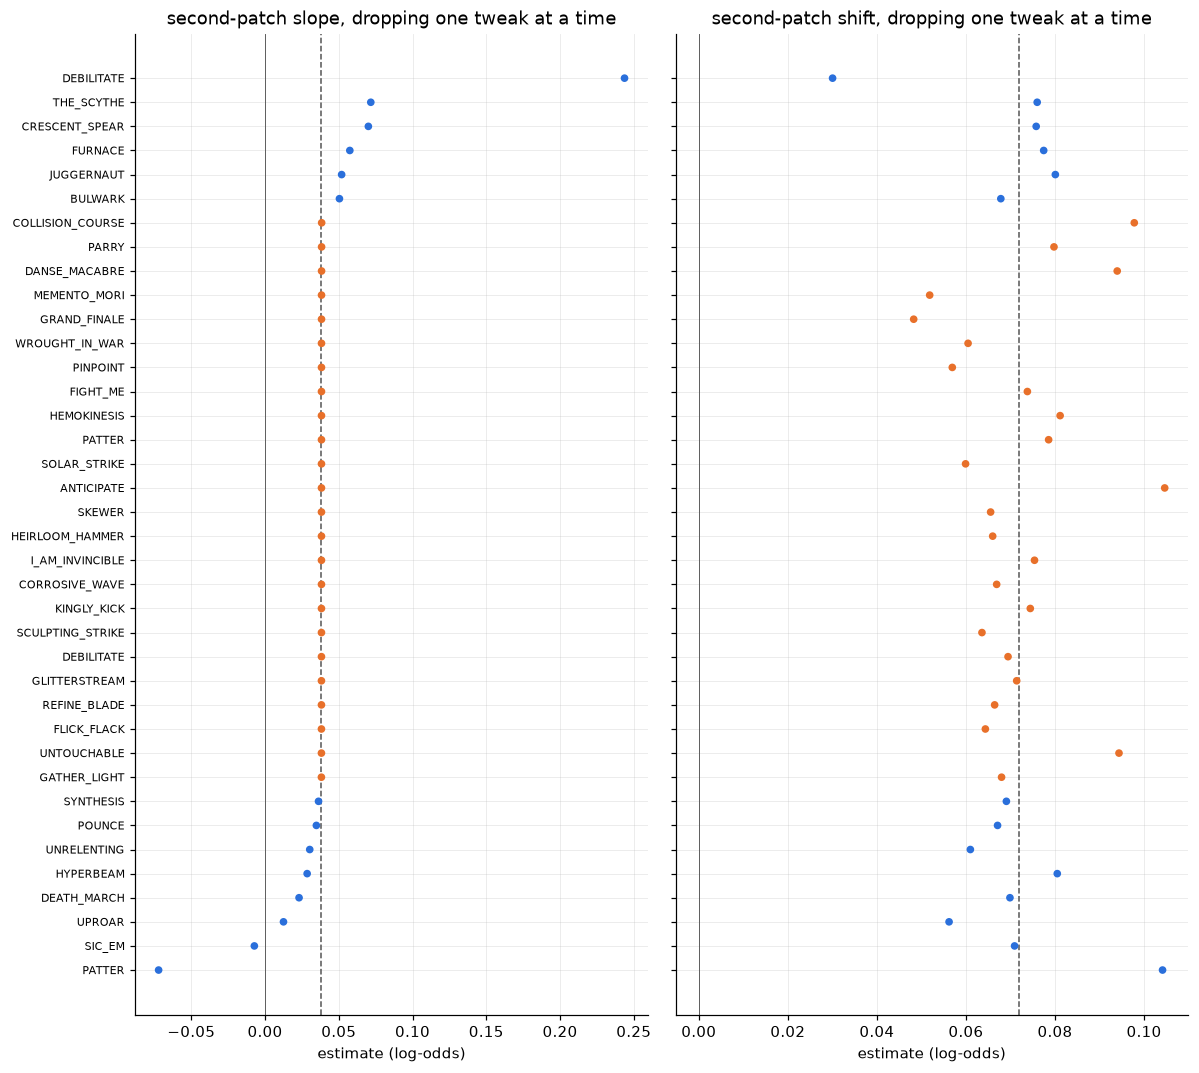

In [ ]:
L = LOO.sort_values("slope_second").reset_index(drop=True)
colors = np.where(L.dropped_patch == SECOND, CONTROL_C, TREATED_C)
fig, axes = plt.subplots(1, 2, figsize=(11, 0.22 * len(L) + 1.5), sharey=True)
yy = np.arange(len(L))
for ax, col, base_val, title in [(axes[0], "slope_second", b0.slope_second, "second-patch slope"),
                                 (axes[1], "patch_shift", b0.patch_shift, "second-patch shift")]:
    ax.axvline(base_val, color=GREY, lw=1, ls="--")
    ax.axvline(0, color=GREY, lw=0.6)
    ax.scatter(L[col], yy, c=colors, zorder=3)
    ax.set(title=f"{title}, dropping one tweak at a time", xlabel="estimate (log-odds)")
axes[0].set_yticks(yy, L.dropped, fontsize=7)
plt.tight_layout()
plt.show()

## 5. Predict patch 2 from patch 1

A different way to see the same gap. Fit *only* the first patch (a line through its points),
then compute where each second-patch tweak would land if the second patch behaved like the
first, and how far off it is.

- `pred`: the first-patch line at that tweak's dose.
- `resid`: actual minus predicted. Negative means the tweak moved picks less than a
  first-patch tweak of that size.
- `z_resid`: `resid` over a rough error bar that combines the point's own uncertainty, the
  card-to-card scatter (τ²) and the uncertainty of the first-patch line. It is approximate.

This separates two ideas the plot mixes up. A line can be *flat* (slope 0) and *low*
(shift below zero) independently. If most residuals are negative, the whole patch sits lower.
If they are negative mainly for big doses, the slope is what differs. Also check that the
second patch's doses are inside the first patch's range: a line shouldn't be trusted far
outside the data it was fitted to.

In [ ]:
def first_patch_line(d):
    y, se = d.beta_lo.to_numpy(), d.se_lo.to_numpy()
    X = np.column_stack([np.ones(len(d)), d.x.to_numpy()])
    b, s, tau2, Q, dof = meta_regression(y, se, X)
    ws = 1 / (se ** 2 + tau2)
    cov = np.linalg.inv((X.T * ws) @ X)
    return b, cov, tau2

f1 = line[line.second == 0]
s2 = line[line.second == 1].copy()
b1, cov1, tau1 = first_patch_line(f1)
s2["pred"] = b1[0] + b1[1] * s2.x
var_pred = cov1[0, 0] + 2 * cov1[0, 1] * s2.x + cov1[1, 1] * s2.x ** 2
s2["resid"] = s2.beta_lo - s2.pred
s2["z_resid"] = s2.resid / np.sqrt(s2.se_lo ** 2 + tau1 + var_pred)

print(f"first-patch line: intercept {b1[0]:.3f}, slope {b1[1]:.3f}, tau2 {tau1:.3f}")
print(f"dose range, first patch: {f1.x.min():.2f} to {f1.x.max():.2f}; "
      f"second patch: {s2.x.min():.2f} to {s2.x.max():.2f}")
print(f"{int((s2.resid < 0).sum())} of {len(s2)} second-patch tweaks sit below the "
      f"first-patch line; mean z_resid {s2.z_resid.mean():.2f}")
display(s2.sort_values("z_resid")[["card_id", "kind", "both_patches", "x", "beta_lo", "se_lo",
                                   "pred", "resid", "z_resid"]].round(3))

first-patch line: intercept -0.025, slope 1.445, tau2 0.064
dose range, first patch: -0.41 to 0.51; second patch: -0.41 to 0.41
9 of 14 second-patch tweaks sit below the first-patch line; mean z_resid -0.42


,card_id,kind,both_patches,x,beta_lo,se_lo,pred,resid,z_resid
card_patch_id,,,,,,,,,
THE_SCYTHE@v0.107.1/patch,THE_SCYTHE,other,False,0.288,-0.049,0.066,0.391,-0.440,-1.635
CRESCENT_SPEAR@v0.107.1/patch,CRESCENT_SPEAR,damage,False,0.288,-0.038,0.038,0.391,-0.429,-1.626
SIC_EM@v0.107.1/patch,SIC_EM,power amount,False,0.406,0.135,0.051,0.561,-0.426,-1.572
FURNACE@v0.107.1/patch,FURNACE,other,False,0.223,-0.047,0.047,0.297,-0.344,-1.305
JUGGERNAUT@v0.107.1/patch,JUGGERNAUT,power amount,False,0.182,-0.077,0.059,0.238,-0.315,-1.188
DEATH_MARCH@v0.107.1/patch,DEATH_MARCH,other,False,0.288,0.106,0.067,0.391,-0.284,-1.055
HYPERBEAM@v0.107.1/patch,HYPERBEAM,damage,False,0.074,-0.058,0.092,0.082,-0.140,-0.509
SYNTHESIS@v0.107.1/patch,SYNTHESIS,damage,False,0.154,0.091,0.061,0.198,-0.106,-0.401
POUNCE@v0.107.1/patch,POUNCE,damage,False,0.154,0.118,0.051,0.198,-0.079,-0.301


**Plot.** The first-patch line is extended across the plot with a band
showing where first-patch-like points would be expected to land. Only the labels that matter
are drawn, to keep it readable: cards changed in both patches (ringed in black) and
second-patch points more than `LABEL_Z` away from the line. Change `LABEL_Z` to taste.

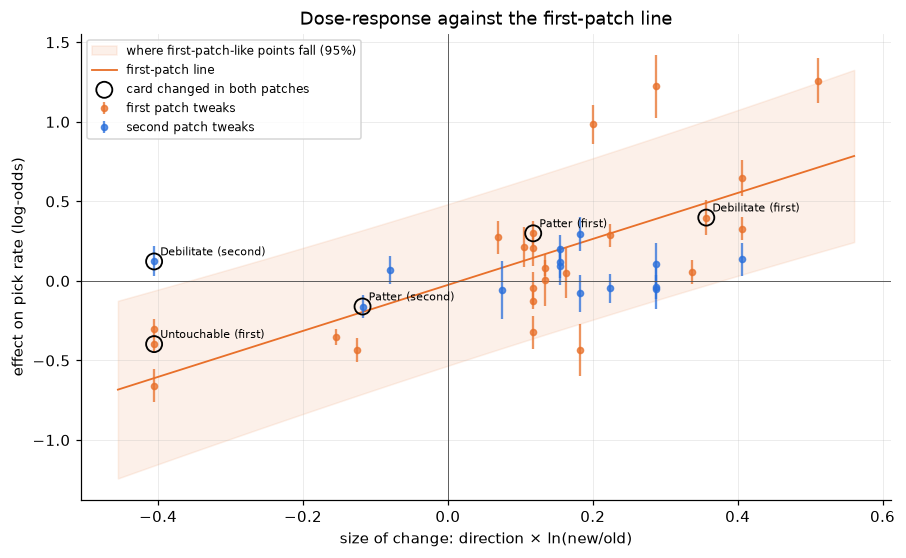

In [ ]:
LABEL_Z = 2.0
xs = np.linspace(line.x.min() - 0.05, line.x.max() + 0.05, 200)
yhat = b1[0] + b1[1] * xs
vp = cov1[0, 0] + 2 * cov1[0, 1] * xs + cov1[1, 1] * xs ** 2
band = 1.96 * np.sqrt(vp + tau1)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.fill_between(xs, yhat - band, yhat + band, color=TREATED_C, alpha=0.10,
                label="where first-patch-like points fall (95%)")
ax.plot(xs, yhat, color=TREATED_C, lw=1.2, label="first-patch line")
for sec, col, lab in [(0, TREATED_C, FIRST), (1, CONTROL_C, SECOND)]:
    g = line[line.second == sec]
    ax.errorbar(g.x, g.beta_lo, yerr=1.96 * g.se_lo, fmt="o", color=col, ecolor=col,
                alpha=0.75, capsize=0, label=f"{lab} tweaks")
bp = line[line.both_patches]
ax.scatter(bp.x, bp.beta_lo, s=110, facecolors="none", edgecolors="black", lw=1.2,
           label="card changed in both patches", zorder=4)
lab_rows = pd.concat([bp, s2[s2.z_resid.abs() > LABEL_Z]]).drop_duplicates(subset=["card_id", "patch"])
for _, r in lab_rows.iterrows():
    ax.annotate(f"{r.card_id.replace('_', ' ').title()} ({r.patch.split()[0]})", (r.x, r.beta_lo),
                fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.axhline(0, color=GREY, lw=0.6)
ax.axvline(0, color=GREY, lw=0.6)
ax.set(xlabel="size of change: direction × ln(new/old)", ylabel="effect on pick rate (log-odds)",
       title="Dose-response against the first-patch line")
ax.legend(fontsize=8)
plt.show()

## 6. Slopes by kind of number

The baseline puts a +1 damage change, a +1 block change and a +1 power-amount change on one
ruler, and assumes they all move picks per unit of `ln(new/old)` the same way. Here each kind
gets its own slope. The model has one intercept, one second-patch shift, and a slope per kind,
**pooling both patches** because the second patch alone has too few points per kind.

If the kind slopes differ a lot (for example damage steep, power amounts flat), the single
ruler is mixing things that shouldn't be mixed, and the pooled slope is an average of unlike
parts. "Other" is a grab-bag: read it as a nuisance term. Kinds with fewer than 3 points are
left out of the model (their points stay in the intercept only).

In [ ]:
counts = line.kind.value_counts()
KINDS = [kd for kd in ["damage", "block", "power amount", "other"] if counts.get(kd, 0) >= 3]
Xk = np.column_stack([np.ones(len(line)), line.second.to_numpy()]
                     + [(line.x * (line.kind == kd)).to_numpy() for kd in KINDS])
labels = ["intercept a", "second-patch shift c"] + [f"slope, {kd} (n={counts[kd]})" for kd in KINDS]
bk, sk, tau_k, Qk, dfk = meta_regression(line.beta_lo, line.se_lo, Xk)
KT = pd.DataFrame(dict(term=labels, coef=bk, se=sk, z=bk / sk)).set_index("term")
one = dose_response_fits(line.beta_lo, line.se_lo, line.x, line.second)
tau_one = one[one.model == "+ patch shift"].tau2.iloc[0]
print(f"tau2 {tau_k:.3f} with slopes by kind; {tau_one:.3f} with one slope")
display(KT.round(3))

tau2 0.071 with slopes by kind; 0.061 with one slope


,coef,se,z
term,,,
intercept a,0.024,0.063,0.376
second-patch shift c,-0.083,0.093,-0.887
"slope, damage (n=18)",0.931,0.443,2.103
"slope, block (n=6)",1.019,0.569,1.790
"slope, power amount (n=7)",1.282,0.274,4.678
"slope, other (n=7)",0.740,0.343,2.156


## 7. Limits

This notebook can only say whether the *dose definition and a few influential points* explain
the flat second-patch slope. It cannot say whether the thin "before" block drifted (v0.103.3 was
stable for about three weeks: released 2026-05-29, followed by v0.107.1 on 2026-06-18, per
`reference/builds.csv`), or whether the players still on the stable branch changed. Those need
the run-level data, so they belong in notebook 02's placebo machinery or a new notebook.

A flat slope that survives the variants is itself a result: the second patch's effects would be
roughly constant whatever the size of the change. Candidate reasons are a shared shift from drift
in a short "before" period, or carryover from the first patch. The placebo and pre-trend checks
in notebook 02 bear on the first one.

In [ ]:
H = pd.read_parquet("data/analysis/did_h3.parquet")
cols = ["card_id", "before_builds", "treated_rate_before", "treated_rate_after",
        "control_rate_before", "control_rate_after"]
print(H[H.card_id.isin(["REFLECT", "BULWARK", "DEBILITATE", "PATTER"])][cols].round(3))

                              card_id before_builds  treated_rate_before  treated_rate_after  control_rate_before  control_rate_after
card_patch_id                                                                                                                        
PATTER@v0.103.2/patch          PATTER       v0.99.1                0.186               0.230                0.276               0.272
DEBILITATE@v0.103.2/patch  DEBILITATE       v0.99.1                0.189               0.254                0.240               0.248
BULWARK@v0.107.1/patch        BULWARK      v0.103.3                0.500               0.520                0.255               0.252
PATTER@v0.107.1/patch          PATTER      v0.103.3                0.259               0.225                0.255               0.252
REFLECT@v0.107.1/patch        REFLECT      v0.103.3                0.549               0.579                0.255               0.252
DEBILITATE@v0.107.1/patch  DEBILITATE      v0.103.3           

In [ ]:
H = pd.read_parquet("data/analysis/did_h3.parquet")
cols = ["card_id", "treated_rate_before", "treated_rate_after",
        "control_rate_before", "control_rate_after", "n_treated_offers"]
print(H[H.before_builds == "v0.103.3"][cols].round(3))

                                      card_id  treated_rate_before  treated_rate_after  control_rate_before  control_rate_after  n_treated_offers
card_patch_id                                                                                                                                    
BULWARK@v0.107.1/patch                BULWARK                0.500               0.520                0.255               0.252              9980
CRESCENT_SPEAR@v0.107.1/patch  CRESCENT_SPEAR                0.194               0.181                0.255               0.252             27622
FURNACE@v0.107.1/patch                FURNACE                0.376               0.361                0.255               0.252             10084
PATTER@v0.107.1/patch                  PATTER                0.259               0.225                0.255               0.252             20410
REFLECT@v0.107.1/patch                REFLECT                0.549               0.579                0.255               0.